# Calidad de datos del dataset integrado

Esta libreta valida, con **pandera**, el dataset que produce `integracion_agricultura_clima.ipynb`:
`data/processed/agricultura_clima_edafologia_historial_2003_2025.csv`. Es la versión más completa (agrícola + clima + edafología + historial) y la entrada del modelado.

Los esquemas viven en `proyecto_agronomia/validation.py`. La libreta **solo reporta**: no modifica ni guarda datos.

Se revisan tres frentes:
1. **Integridad**: tipos, dominios, formato de `cvegeo`, llave única y correspondencia código ↔ nombre.
2. **Límites y reglas de negocio**: superficies (Sembrada, Cosechada y Siniestrada están todas en **hectáreas** según el diccionario DGSIAP), coherencia producción–rendimiento–valor y rangos de clima, suelo e historial.
3. **Valores faltantes**: separando los esperados de los inesperados.

Cada regla queda como **OK**, **Falla** o **Advertencia** (incumplimiento esperado u orientativo, como la cobertura de suelo en municipios costeros).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import pandera

from proyecto_agronomia import validation as val

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 200)
print("pandera", pandera.__version__, "| pandas", pd.__version__)

2026-11-21 10:02:23.078 | INFO     | proyecto_agronomia.config:<module>:15 - PROJ_ROOT path is: B:\MCD2\JW\agro\proyecto_agronomia


B:\MCD2\JW\agro\proyecto_agronomia
pandera 0.36.0 | pandas 3.0.6


## 1. Carga y forma general

Invariantes del proyecto: la integración no crea ni elimina registros (825,089) y hay 2,478 municipios INEGI (no todos tienen producción agrícola).

In [2]:
REGISTROS_ESPERADOS = 825_089
MUNICIPIOS_INEGI = 2_478

df = val.cargar_dataset_integrado()
n = len(df)

print(f"Registros: {n:,}  (esperados {REGISTROS_ESPERADOS:,}) -> {'OK' if n == REGISTROS_ESPERADOS else 'DIFERENTE'}")
print(f"Columnas: {df.shape[1]}")
print(f"Municipios con producción: {df['cvegeo'].nunique():,} de {MUNICIPIOS_INEGI:,} INEGI")
print(f"Años: {df['Anio'].min()}–{df['Anio'].max()}  ({df['Anio'].nunique()} años)")
print(f"Filas duplicadas completas: {df.duplicated().sum():,}")

Registros: 825,089  (esperados 825,089) -> OK
Columnas: 73
Municipios con producción: 2,452 de 2,478 INEGI
Años: 2003–2025  (23 años)
Filas duplicadas completas: 0


## 2. Bloque agrícola: integridad y reglas de negocio

`esquema_agricola` revisa tipos, dominios (ciclo, modalidad, unidad), formato de `cvegeo`, no negatividad y unicidad de la llave del registro:
`Anio, cvegeo, Idddr, Idcader, Idciclo, Idmodalidad, Idcultivo, Idunidadmedida`. Un municipio puede repartirse entre varios DDR/CADER, por eso forman parte de la llave.

Las reglas de superficie comparan hectáreas con hectáreas (tolerancia 0.01 ha):
- Cosechada ≤ Sembrada, Siniestrada ≤ Sembrada y Cosechada + Siniestrada ≤ Sembrada.
- En cultivos anuales (O-I y P-V): Cosechada + Siniestrada = Sembrada.
- En perennes no debería haber superficie siniestrada (diccionario DGSIAP); se reporta como advertencia.

In [3]:
fallas_agricola = val.validar(df, val.esquema_agricola)
resumen_agricola = val.resumen_fallas(fallas_agricola, val.esquema_agricola, n)
resumen_agricola.query("estado != 'OK'")

,esquema,columna,regla,descripcion,registros,pct_registros,estado
0,agricola,agricola,cosechada_mas_siniestrada_le_sembrada,Cosechada + Siniestrada no puede superar a Sembrada.,3,0.0004,Falla
1,agricola,agricola,cosechada_le_sembrada,Cosechada no puede superar a Sembrada.,2,0.0002,Falla
2,agricola,agricola,volumen_cero_si_cosechada_cero,Sin superficie cosechada no puede haber volumen de producción.,2,0.0002,Falla
3,agricola,agricola,valor_consistente,Valorproduccion ≈ Volumen × Precio (tolerancia 1 %).,1,0.0001,Falla
4,agricola,agricola,cvegeo_un_solo_Nommunicipio,Cada cvegeo debe tener un único Nommunicipio.,6342,0.7686,Advertencia
5,agricola,agricola,Idestado_un_solo_Nomestado,Cada Idestado debe tener un único Nomestado.,4876,0.5910,Advertencia
6,agricola,agricola,Idcultivo_un_solo_Nomcultivo,Cada Idcultivo debe tener un único Nomcultivo.,277,0.0336,Advertencia
7,agricola,agricola,perennes_sin_siniestrada,"Según DGSIAP, la superficie siniestrada solo aplica a cultivos anuales.",215,0.0261,Advertencia


In [4]:
COLUMNAS_EJEMPLO = [
    "Anio", "Nomestado", "cvegeo", "Nommunicipio", "Nomcultivo", "Nomcicloproductivo",
    "Sembrada", "Cosechada", "Siniestrada", "Volumenproduccion", "Rendimiento",
    "Preciomediorural", "Valorproduccion",
]
reglas_superficie = [
    "cosechada_le_sembrada", "cosechada_mas_siniestrada_le_sembrada",
    "volumen_cero_si_cosechada_cero", "valor_consistente",
]
for regla in reglas_superficie:
    idx = val.indices_con_falla(fallas_agricola, regla)
    print(f"\n### {regla}: {len(idx)} registro(s)")
    display(df.loc[idx, COLUMNAS_EJEMPLO])


### cosechada_le_sembrada: 2 registro(s)


,Anio,Nomestado,cvegeo,Nommunicipio,Nomcultivo,Nomcicloproductivo,Sembrada,Cosechada,Siniestrada,Volumenproduccion,Rendimiento,Preciomediorural,Valorproduccion
810046,2025,Oaxaca,20168,San José Estancia Grande,Pastos y praderas,Perennes,1062.80,1063.14,0.0,14418.43,13.56,417.60,6021087.74
810212,2025,Oaxaca,20485,Santiago Tapextla,Pastos y praderas,Perennes,1205.02,1206.63,0.0,15595.02,12.92,404.32,6305321.01



### cosechada_mas_siniestrada_le_sembrada: 3 registro(s)


,Anio,Nomestado,cvegeo,Nommunicipio,Nomcultivo,Nomcicloproductivo,Sembrada,Cosechada,Siniestrada,Volumenproduccion,Rendimiento,Preciomediorural,Valorproduccion
609056,2019,Querétaro,22014,Querétaro,Tuna,Perennes,20.00,20.00,15.0,40.00,2.00,1025.00,41000.00
810046,2025,Oaxaca,20168,San José Estancia Grande,Pastos y praderas,Perennes,1062.80,1063.14,0.0,14418.43,13.56,417.60,6021087.74
810212,2025,Oaxaca,20485,Santiago Tapextla,Pastos y praderas,Perennes,1205.02,1206.63,0.0,15595.02,12.92,404.32,6305321.01



### volumen_cero_si_cosechada_cero: 2 registro(s)


,Anio,Nomestado,cvegeo,Nommunicipio,Nomcultivo,Nomcicloproductivo,Sembrada,Cosechada,Siniestrada,Volumenproduccion,Rendimiento,Preciomediorural,Valorproduccion
244404,2009,Sonora,26032,Huásabas,Frijol,Primavera-Verano,6.0,0.0,6.0,2.4,NaN,0.0,0.0
244412,2009,Sonora,26067,Villa Hidalgo,Frijol,Primavera-Verano,38.0,0.0,38.0,15.2,NaN,0.0,0.0



### valor_consistente: 1 registro(s)


,Anio,Nomestado,cvegeo,Nommunicipio,Nomcultivo,Nomcicloproductivo,Sembrada,Cosechada,Siniestrada,Volumenproduccion,Rendimiento,Preciomediorural,Valorproduccion
769609,2024,Nayarit,18015,Santiago Ixcuintla,Plantero de tabaco,Otoño-Invierno,6.0,6.0,0.0,28119000.0,4686500.0,0.36,10260000.0


In [5]:
def nombres_por_codigo(codigo, nombre):
    """Códigos con más de un nombre, con los años en que aparece cada variante."""
    variantes = df.groupby([codigo, nombre])["Anio"].agg(["min", "max", "size"]).reset_index()
    multiples = variantes.groupby(codigo)[nombre].transform("nunique").gt(1)
    return variantes[multiples].rename(columns={"min": "anio_min", "max": "anio_max", "size": "registros"})

for codigo, nombre in [("Idestado", "Nomestado"), ("Idcultivo", "Nomcultivo"), ("cvegeo", "Nommunicipio")]:
    tabla = nombres_por_codigo(codigo, nombre)
    print(f"\n### {codigo} con más de un {nombre}: {tabla[codigo].nunique()}")
    display(tabla)


### Idestado con más de un Nomestado: 1


,Idestado,Nomestado,anio_min,anio_max,registros
8,9,Ciudad de México,2015,2025,2231
9,9,Ciudad de México / DF,2003,2014,2645



### Idcultivo con más de un Nomcultivo: 4


,Idcultivo,Nomcultivo,anio_min,anio_max,registros
33,5270000,Alpiste,2003,2025,153
34,5270000,Alpiste grano,2015,2019,18
36,5320000,Alpiste forrajero verde,2016,2018,2
37,5320000,Alpiste verde,2008,2023,4
216,7230000,Jengibre,2022,2025,20
217,7230000,Jenjibre,2003,2019,35
394,9250000,Semilla de pastos y praderas,2003,2025,42
395,9250000,Semilla de zacate,2015,2017,3



### cvegeo con más de un Nommunicipio: 15


,cvegeo,Nommunicipio,anio_min,anio_max,registros
99,07017,Cintalapa,2003,2023,357
100,07017,Cintalapa de Figueroa,2024,2025,34
215,08008,Batopilas,2003,2023,149
216,08008,Batopilas de Manuel Gómez Morín,2024,2025,12
905,17013,Jonacatepec,2003,2023,585
906,17013,Jonacatepec de Leandro Valle,2024,2025,64
925,17032,Zacualpan,2003,2023,417
926,17032,Zacualpan de Amilpas,2024,2025,52
1036,20038,Villa Hidalgo,2003,2023,111
1037,20038,Villa Hidalgo Yalálag,2024,2025,13


In [6]:
perennes_siniestrados = df.loc[val.indices_con_falla(fallas_agricola, "perennes_sin_siniestrada")]
print("Perennes con superficie siniestrada, por año:")
display(perennes_siniestrados["Anio"].value_counts().sort_index().to_frame("registros").T)
print("Cultivos más frecuentes:")
display(perennes_siniestrados["Nomcultivo"].value_counts().head(10).to_frame("registros").T)

Perennes con superficie siniestrada, por año:


Anio,2019,2020,2023,2024,2025
registros,53,111,6,7,38


Cultivos más frecuentes:


Nomcultivo,Naranja,Limón,Caña de azúcar,Aguacate,Papaya,Toronja,Pastos y praderas,Espárrago,Maguey pulquero,Higuerilla
registros,35,27,21,17,10,9,9,8,6,6


In [7]:
# Rendimiento por unidad de medida (descriptivo): las escalas no son comparables entre unidades.
(
    df.groupby("Nomunidad")["Rendimiento"]
    .describe(percentiles=[0.5, 0.99])
    .round(2)
    .sort_values("count", ascending=False)
)

,count,mean,std,min,50%,99%,max
Nomunidad,,,,,,,
Tonelada,812456.0,15.77,40.02,0.0,7.0,123.00,16320.00
Gruesa,5831.0,1967.02,2196.64,0.0,1200.0,10312.00,15336.29
Planta,2274.0,302449.67,941305.36,0.0,70000.0,4690145.00,10598037.38
Miles de lts.,1927.0,63.25,48.97,0.0,73.0,195.18,240.00
Manojo,1439.0,8596.09,13732.14,0.0,2260.0,50646.24,80000.00
Metro cuadrado,287.0,9575.30,1401.41,0.0,9980.0,10484.52,10796.46


## 3. Clima, edafología e historial

- **Clima** (NASA POWER): temperaturas mensuales y del ciclo en [−10, 45] °C, precipitación mensual en [0, 1,500] mm y por ciclo en [0, 6,000] mm, y días de clima acordes al ciclo (~6 meses en anuales, un año en perennes).
- **Edafología**: `suelo_pct_*` en [0, 100], suma ≤ 100.5 %, grupo dominante igual al de mayor porcentaje. La suma < 95 % en municipios costeros es esperada (la capa no cubre lagunas ni mar) y se reporta como advertencia.
- **Historial**: estadísticos sin fuga temporal; la media, desviación y CV históricos requieren al menos 3 años previos.

In [8]:
resumenes = {"agricola": resumen_agricola}
fallas = {"agricola": fallas_agricola}
for nombre in ["clima", "edafologia", "historial"]:
    esquema = val.ESQUEMAS[nombre]
    fallas[nombre] = val.validar(df, esquema)
    resumenes[nombre] = val.resumen_fallas(fallas[nombre], esquema, n)
    conteo = resumenes[nombre]["estado"].value_counts().to_dict()
    print(f"{nombre:<11} {conteo}")

pd.concat([resumenes[k] for k in ["clima", "edafologia", "historial"]]).query("estado != 'OK'")

clima       {'OK': 16}
edafologia  {'OK': 18, 'Falla': 1, 'Advertencia': 1}
historial   {'OK': 14}


,esquema,columna,regla,descripcion,registros,pct_registros,estado
0,edafologia,nombre_suelo_wrb,not_nullable,Sin valores faltantes.,3225,0.3909,Falla
1,edafologia,edafologia,suelo_cubre_95pct_municipio,La capa de suelo cubre al menos 95 % del municipio (falla en costas; esperado).,825089,100.0000,Advertencia


In [9]:
# Municipios con cobertura de suelo < 95 % (esperado en costas)
columnas_suelo = df.filter(regex=r"^suelo_pct_").columns
cobertura = (
    df.drop_duplicates("cvegeo")
    .assign(cobertura_suelo_pct=lambda d: d[columnas_suelo].sum(axis=1).round(2))
    .query("cobertura_suelo_pct < 95")[["cvegeo", "Nomestado", "Nommunicipio", "cobertura_suelo_pct"]]
    .sort_values("cobertura_suelo_pct")
    .reset_index(drop=True)
)
print(f"{len(cobertura)} municipios")
cobertura

2452 municipios


,cvegeo,Nomestado,Nommunicipio,cobertura_suelo_pct
0,01001,Aguascalientes,Aguascalientes,0.0
1,01005,Aguascalientes,Jesús María,0.0
2,01010,Aguascalientes,El Llano,0.0
3,01011,Aguascalientes,San Francisco de Los Romo,0.0
4,01003,Aguascalientes,Calvillo,0.0
...,...,...,...,...
2447,02006,Baja California,San Quintín,0.0
2448,04013,Campeche,Dzitbalché,0.0
2449,04012,Campeche,Seybaplaya,0.0
2450,07125,Chiapas,Honduras de la Sierra,0.0


## 4. Valores faltantes

Se separan los faltantes **esperados** (con explicación) de los **inesperados**. Además se revisa cómo se codifica la ausencia de producción: con Cosechada = 0, el rendimiento a veces viene como nulo y a veces como 0.

In [10]:
faltantes = val.reporte_faltantes(df)
print(faltantes["estado"].value_counts().to_dict())
faltantes.query("faltantes > 0")

{'OK': 60, 'Esperado': 8, 'Inesperado': 5}


,faltantes,pct_faltantes,esperado,explicacion,estado
columna,,,,,
fase_quimica_dominante,497983,60.3551,False,,Inesperado
fase_quimica_dominante_pct,497983,60.3551,False,,Inesperado
rendimiento_hist_cv,181430,21.9891,True,Menos de 3 años previos con rendimiento (minimo_periodos=3).,Esperado
rendimiento_hist_desviacion,181430,21.9891,True,Menos de 3 años previos con rendimiento (minimo_periodos=3).,Esperado
rendimiento_hist_media,181430,21.9891,True,Menos de 3 años previos con rendimiento (minimo_periodos=3).,Esperado
rendimiento_anio_anterior,82110,9.9517,True,Primer año de la serie o año previo sin cosecha.,Esperado
fase_fisica_dominante_pct,36414,4.4133,False,,Inesperado
fase_fisica_dominante,36414,4.4133,False,,Inesperado
nombre_suelo_wrb,3225,0.3909,False,,Inesperado


In [11]:
# Codificación de "sin cosecha": ¿nulo o cero? Por año.
sin_cosecha = df.loc[df["Cosechada"].eq(0)]
codificacion = (
    sin_cosecha.assign(
        rendimiento=lambda d: d["Rendimiento"].isna().map({True: "nulo", False: "cero"})
    )
    .groupby(["Anio", "rendimiento"])
    .size()
    .unstack(fill_value=0)
)
codificacion.T

Anio,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
rendimiento,,,,,,,,,,,,,,,,,,,,,
cero,1324,1266,1758,1379,1268,1209,1593,1328,1939,1043,...,567,531,503,517,346,275,326,493,0,0
nulo,0,0,0,0,0,0,2,0,0,0,...,0,0,0,0,0,0,0,0,458,415


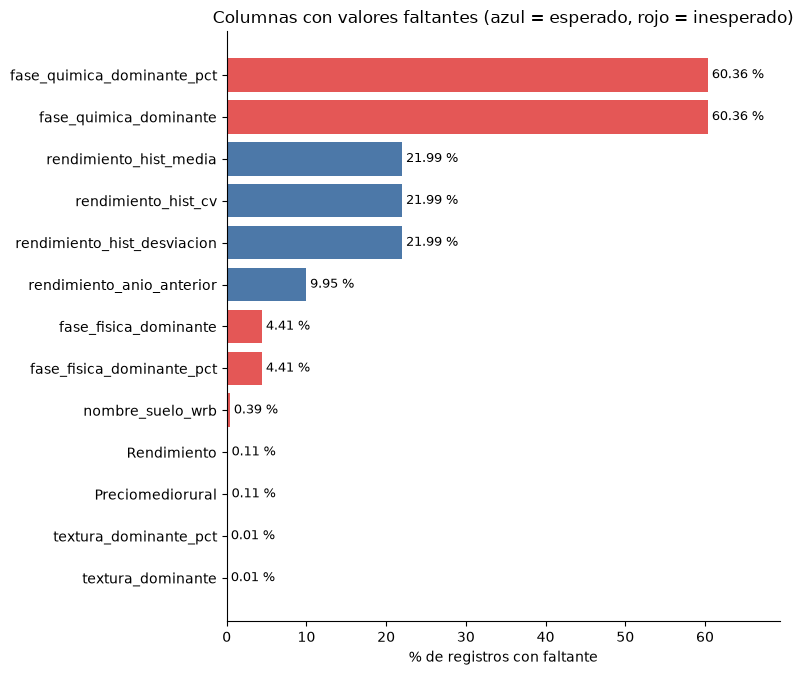

In [12]:
con_faltantes = faltantes.query("faltantes > 0").sort_values("pct_faltantes")
colores = con_faltantes["estado"].map({"Esperado": "#4C78A8", "Inesperado": "#E45756"})

fig, ax = plt.subplots(figsize=(8, 0.45 * len(con_faltantes) + 1))
ax.barh(con_faltantes.index, con_faltantes["pct_faltantes"], color=colores)
for y, pct in enumerate(con_faltantes["pct_faltantes"]):
    ax.text(pct, y, f" {pct:.2f} %", va="center", fontsize=9)
ax.set_xlabel("% de registros con faltante")
ax.set_title("Columnas con valores faltantes (azul = esperado, rojo = inesperado)")
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(0, con_faltantes["pct_faltantes"].max() * 1.15)
plt.tight_layout()
plt.show()

## 5. Resumen de reglas

Todas las reglas de los cuatro esquemas, con su estado y el número de registros afectados.

In [13]:
resumen = pd.concat(resumenes.values(), ignore_index=True)
display(resumen.pivot_table(index="esquema", columns="estado", values="regla", aggfunc="count", fill_value=0))
resumen.query("estado != 'OK'")[["esquema", "regla", "descripcion", "registros", "pct_registros", "estado"]]

estado,Advertencia,Falla,OK
esquema,,,
agricola,4,4,66
clima,0,0,16
edafologia,1,1,18
historial,0,0,14


,esquema,regla,descripcion,registros,pct_registros,estado
0,agricola,cosechada_mas_siniestrada_le_sembrada,Cosechada + Siniestrada no puede superar a Sembrada.,3,0.0004,Falla
1,agricola,cosechada_le_sembrada,Cosechada no puede superar a Sembrada.,2,0.0002,Falla
2,agricola,volumen_cero_si_cosechada_cero,Sin superficie cosechada no puede haber volumen de producción.,2,0.0002,Falla
3,agricola,valor_consistente,Valorproduccion ≈ Volumen × Precio (tolerancia 1 %).,1,0.0001,Falla
4,agricola,cvegeo_un_solo_Nommunicipio,Cada cvegeo debe tener un único Nommunicipio.,6342,0.7686,Advertencia
5,agricola,Idestado_un_solo_Nomestado,Cada Idestado debe tener un único Nomestado.,4876,0.5910,Advertencia
6,agricola,Idcultivo_un_solo_Nomcultivo,Cada Idcultivo debe tener un único Nomcultivo.,277,0.0336,Advertencia
7,agricola,perennes_sin_siniestrada,"Según DGSIAP, la superficie siniestrada solo aplica a cultivos anuales.",215,0.0261,Advertencia
90,edafologia,not_nullable,Sin valores faltantes.,3225,0.3909,Falla
91,edafologia,suelo_cubre_95pct_municipio,La capa de suelo cubre al menos 95 % del municipio (falla en costas; esperado).,825089,100.0000,Advertencia


## 6. Prueba de sanidad de los esquemas

Para confirmar que los esquemas sí detectan errores, se inyectan fallas conocidas en una copia pequeña del dataset (los datos reales no se tocan).

In [14]:
muestra = df.sample(2_000, random_state=0).reset_index(drop=True)
muestra.loc[0, "Cosechada"] = muestra.loc[0, "Sembrada"] + 5
muestra.loc[1, "Siniestrada"] = muestra.loc[1, "Sembrada"] + 5
muestra.loc[2, "cvegeo"] = "123"
muestra.loc[3, "Volumenproduccion"] = -1.0
muestra.loc[4, "temperatura_ene_c"] = 60.0
muestra = pd.concat([muestra, muestra.iloc[[5]]], ignore_index=True)  # llave duplicada

esperadas = [
    "cosechada_le_sembrada", "siniestrada_le_sembrada", "str_matches('^\\d{5}$')",
    "greater_than_or_equal_to(0)", "in_range(-10, 45)", "multiple_fields_uniqueness",
]
detectadas = set(val.validar(muestra, val.esquema_integrado)["check"].astype(str))
pd.DataFrame({"regla": esperadas, "detectada": [r in detectadas for r in esperadas]})

,regla,detectada
0,cosechada_le_sembrada,True
1,siniestrada_le_sembrada,True
2,str_matches('^\d{5}$'),True
3,greater_than_or_equal_to(0),True
4,"in_range(-10, 45)",True
5,multiple_fields_uniqueness,True


## 7. Conclusiones

**Integridad.** Se conservan los 825,089 registros, no hay filas duplicadas y la llave `Anio, cvegeo, Idddr, Idcader, Idciclo, Idmodalidad, Idcultivo, Idunidadmedida` es única. `cvegeo` siempre tiene 5 dígitos y coincide con `Idestado`. Los bloques de clima, edafología e historial pasan todas sus reglas.

**Fallas reales (6 registros únicos; se sugiere revisarlos antes de modelar):**
- *Cosechada > Sembrada*: 2 registros de Pastos y praderas (perennes, Oaxaca, 2025), excedentes de 0.3 y 1.6 ha.
- *Cosechada + Siniestrada > Sembrada*: además, Tuna perenne en Querétaro (2019), con 15 ha siniestradas sobre 20 sembradas y 20 cosechadas.
- *Volumen sin superficie cosechada*: 2 registros de Frijol P-V en Sonora (2009) totalmente siniestrados pero con volumen.
- *Valor ≠ Volumen × Precio*: 1 registro de Plantero de tabaco (Nayarit, 2024).

**Advertencias (cambios de la fuente, no errores de la integración):**
- Cambios oficiales de nombre con el mismo código: Ciudad de México (2015), 15 municipios (la mayoría en 2024) y 4 cultivos (p. ej. Jenjibre → Jengibre). Conviene agrupar siempre por código, no por nombre; ojo: `CLAVES_HISTORIA` usa `Nomcultivo`.
- Perennes con superficie siniestrada (215 registros): solo aparecen desde 2019, lo que sugiere un cambio en el criterio de captura de la DGSIAP.
- 31 municipios costeros con cobertura de suelo < 95 % (esperado).

**Faltantes.** Todos son esperados. La ausencia de producción se codifica distinto según el año: de 2003 a 2023 el rendimiento y el precio vienen en **0**, y en 2024–2025 vienen **nulos**. Antes de modelar conviene homologar ese criterio.